# Лабораторная работа №2: классификация

**Задача:** по данным о пассажире «Титаника» предсказать, выжил он (`Survived = 1`) или погиб (`Survived = 0`).

**Метрика:** основная — F1 для класса «выжил», порог F1 > 0.70. Дополнительно считаем Accuracy, Precision и Recall.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
RANDOM_STATE = 42

## Данные

In [2]:
# Titanic Dataset — тот же файл, что на Kaggle (891 пассажир)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
print("Пропуски:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nДубликатов:", df.duplicated().sum())
print("\nУникальных значений в столбцах:")
df.nunique()

Пропуски:
Age         177
Cabin       687
Embarked      2
dtype: int64

Дубликатов: 0

Уникальных значений в столбцах:


PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

**Выводы.**
- 891 пассажир, 12 столбцов, дубликатов нет.
- Пропуски есть в трёх столбцах: `Age` (177, это 20%), `Cabin` (687, это 77%) и `Embarked` (2).
- Признаки, которые нельзя брать как есть:
  - `PassengerId` и `Name` уникальны у каждого пассажира, `Ticket` почти уникален (681 значение на 891 человека). По сути это идентификаторы: модель не найдёт в них закономерность, а просто запомнит, кто из конкретных людей выжил. Эти столбцы не используем. Из имени берём только обращение (см. ниже).
  - `Cabin` почти пустой, и почти все значения в нём уникальны. Не используем.
- `Sex`, `Embarked`, `Pclass` — категориальные признаки, их нужно перевести в числа.

In [5]:
df["Survived"].value_counts(normalize=True)

Survived
0   0.616
1   0.384
Name: proportion, dtype: float64

Выжили 38% пассажиров, погибли 62%. Классы несбалансированы: если всегда отвечать «погиб», accuracy уже будет 62%. Поэтому accuracy здесь мало что говорит, и основная метрика — F1.

In [6]:
# Из имени достаём только обращение: Mr, Mrs, Miss, Master; редкие (Dr, Rev, Col...) объединяем в Rare
df["Title"] = df["Name"].str.extract(r",\s*([^.]+)\.")[0]
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df.loc[~df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"
df["Title"].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

Обращение — не идентификатор: оно одинаковое у многих пассажиров и несёт смысл. По нему видны пол, возраст (Master — это мальчик) и семейное положение (Mrs — замужняя женщина). Поэтому из `Name` оставляем только этот признак `Title`. Это та «отдельная обработка» признака, о которой говорит задание.

## Разбиение на train и test

In [7]:
# Признаки для модели. PassengerId, Name, Ticket и Cabin не берём
num = ["Age", "Fare", "SibSp", "Parch"]
cat = ["Pclass", "Sex", "Embarked", "Title"]

X = df[num + cat]
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)

pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)})

(712, 8) (179, 8)


,train,test
Survived,,
0,0.617,0.615
1,0.383,0.385


- Делим 80/20: 712 пассажиров в train и 179 в test.
- `stratify=y` сохраняет одинаковую долю выживших (~38%) в обеих частях, это видно в таблице.
- `random_state=42` фиксирует разбиение: оно одинаковое при каждом запуске и совпадает с тестом всей группы.
- Тест используем только для финальной оценки. Модели сравниваем и лучшую выбираем по F1 на кросс-валидации внутри train (`F1 CV`).

## Анализ данных

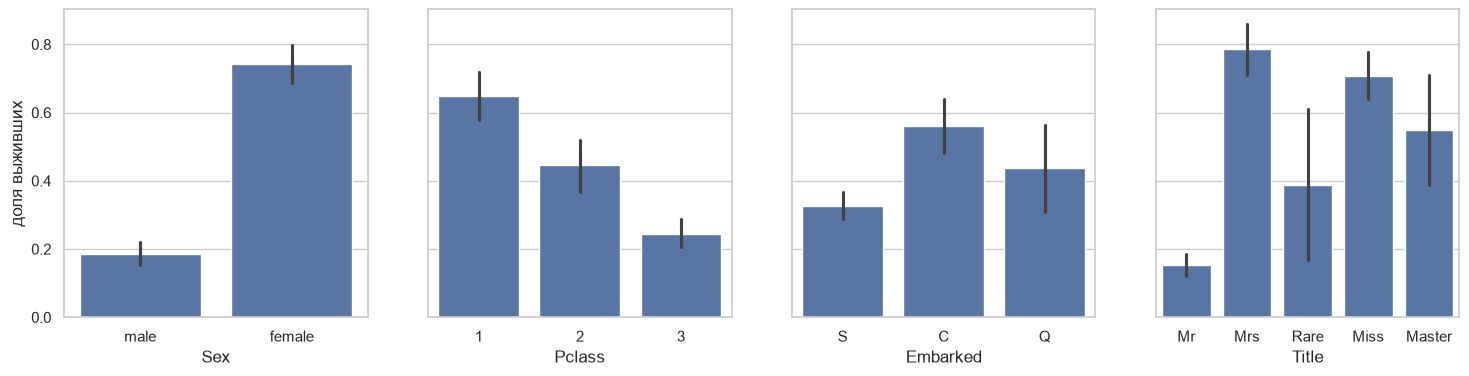

Pclass,1,2,3
Sex,,,
female,0.975,0.914,0.500
male,0.370,0.152,0.135


In [8]:
# Дальше анализ только по train
train = X_train.assign(Survived=y_train)

fig, axs = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, col in zip(axs, ["Sex", "Pclass", "Embarked", "Title"]):
    sns.barplot(data=train, x=col, y="Survived", ax=ax)
    ax.set_ylabel("доля выживших")
plt.show()

train.pivot_table(index="Sex", columns="Pclass", values="Survived")

**Выводы.**
- **Пол — самый сильный фактор.** Выжили 74% женщин и только 19% мужчин. Так работало правило «сначала женщины и дети».
- **Класс билета.** В 1-м классе выжили 65%, во 2-м 45%, в 3-м 24%. Каюты 1-го класса были ближе к шлюпкам.
- **Пол и класс вместе.** Женщины 1-го и 2-го класса выжили почти все (97% и 91%), а женщины 3-го класса — только половина. Среди мужчин в 1-м классе выжили 37%, во 2-м и 3-м — около 14%.
- **Обращение повторяет ту же картину.** Mr — 15%, Miss и Mrs — 71% и 79%, Master (мальчики) — 55%, заметно выше, чем у взрослых мужчин.
- **Порт посадки.** Из Шербура (C) выжили 56%, из Саутгемптона (S) 33%. Но порт тут ни при чём: среди севших в Шербуре 53% — пассажиры 1-го класса, а среди севших в Саутгемптоне — только 18%. Это пример связи через третий признак (класс).

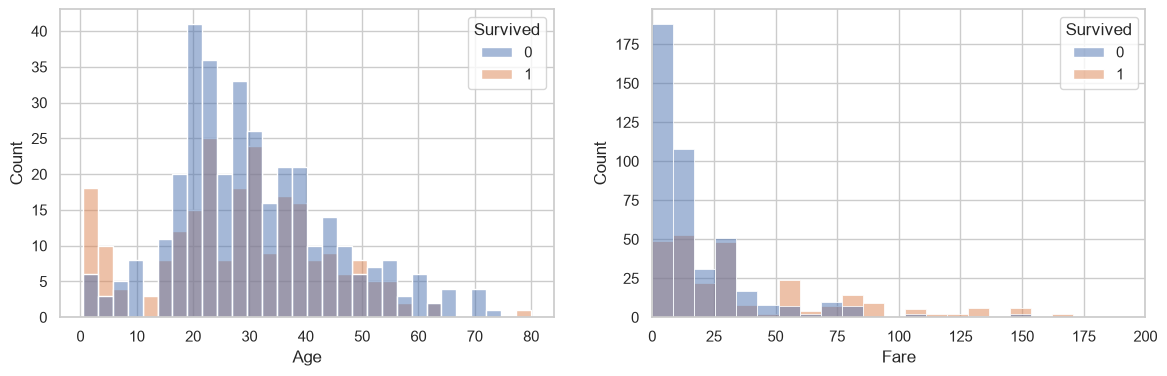

,Age,Fare,SibSp,Parch
Survived,,,,
0,28.250,10.500,0.000,0.000
1,29.000,26.000,0.000,0.000


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=train, x="Age", hue="Survived", bins=30, ax=axs[0])
sns.histplot(data=train, x="Fare", hue="Survived", bins=60, ax=axs[1])
axs[1].set_xlim(0, 200)
plt.show()

train.groupby("Survived")[num].median()

**Выводы.**
- **Возраст.** Медианы у выживших и погибших почти одинаковые (29 и 28), но среди детей до 10 лет выжили 64%. Связь есть, но только для детей, а не прямая «чем старше, тем хуже».
- **Цена билета.** У выживших медиана 26, у погибших 10.5. Дорогой билет — это 1-й класс. В распределении длинный хвост: максимум 512.
- Ожидаем, что для моделей важнее всего будут пол и обращение, класс и цена билета, а возраст — в основном для детей.

## Подготовка данных

- **Пропуски.** `Age` заполняем медианой: она не сдвигается из-за выбросов. `Embarked` заполняем самым частым портом. Медиану и самое частое значение считаем только по train: всё лежит внутри `Pipeline`, который обучается на train и только применяется к test.
- **Категории.** Переводим их в числа через one-hot: каждое значение становится отдельным столбцом из 0 и 1. Просто пронумеровать категории нельзя, потому что тогда модель решит, что между портами S, C и Q есть порядок.
- **Масштабирование.**
  - Нужно только для SVM и KNN: они сравнивают пассажиров по расстоянию, и без масштабирования цена билета (0–512) перевесит все остальные признаки.
  - Деревьям масштаб не важен: они задают вопросы вида «Fare > 50?», и ответ не зависит от единиц измерения.
  - Поэтому делаем два варианта предобработки.

In [10]:
# Для деревьев: заполняем пропуски и кодируем категории (one-hot)
preprocess_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat),
])

# Для SVM и KNN: то же самое + масштабирование числовых признаков
preprocess_scaled = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat),
])

print(X_train.shape, "->", preprocess_tree.fit_transform(X_train).shape)

(712, 8) -> (712, 17)


8 исходных признаков превращаются в 17 столбцов: 4 числовых и 13 one-hot.

## Как подбираем и оцениваем модели

- **Подбор параметров — `RandomizedSearchCV`.**
  - Для каждой модели задаём варианты параметров.
  - Поиск случайно пробует 20 сочетаний и для каждого считает F1 на 5-фолдовой кросс-валидации внутри train.
  - Побеждает сочетание с лучшим F1.
  - Это быстрее полного перебора всех вариантов (`GridSearchCV`), а тест в подборе не участвует.
- **Кросс-валидация.** Train делится на 5 частей. Модель 5 раз учится на четырёх и проверяется на пятой. Получаем 5 значений F1: среднее показывает качество, разброс (±) — насколько оно устойчиво.
- **Функция `evaluate`** для лучшей модели печатает:
  - F1 на каждом фолде кросс-валидации, среднее и разброс;
  - F1 на train;
  - Accuracy, Precision, Recall и F1 на тесте;
  - матрицу ошибок.

**Метрики.**
- **Accuracy** — доля всех правильных ответов.
- **Precision** — из тех, кого модель назвала выжившими, сколько выжили на самом деле.
- **Recall** — из всех выживших, скольких модель нашла.
- **F1** — среднее между Precision и Recall; оно низкое, если низкая хотя бы одна из них.

**Матрица ошибок.** В строках — что было на самом деле, в столбцах — что ответила модель.
- **FP (False Positive)** — модель сказала «выжил», а человек погиб.
- **FN (False Negative)** — модель сказала «погиб», а человек выжил.

Допустим, модель подсказывает, кого спасать в первую очередь. Тогда FN — это человек, которого «списали», хотя он мог выжить. FP — ложная надежда и силы, потраченные не там. По смыслу FN здесь опаснее.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
feature_names = [name.split("__")[1] for name in preprocess_tree.get_feature_names_out()]
results, predictions, models = {}, {}, {}


def evaluate(name, model):
    """Кросс-валидация на train, метрики на test и матрица ошибок для обученной модели."""
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    pred = model.predict(X_test)
    models[name], predictions[name] = model, pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "F1 train": f1_score(y_train, model.predict(X_train)),
        "F1 CV": cv_scores.mean(),
    }
    print("F1 на фолдах кросс-валидации:", cv_scores.round(3))
    print(f"F1 CV = {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
    print(f"F1 train = {results[name]['F1 train']:.3f}, F1 test = {results[name]['F1']:.3f}")
    print(f"Accuracy = {results[name]['Accuracy']:.3f}, Precision = {results[name]['Precision']:.3f}, Recall = {results[name]['Recall']:.3f}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["погиб", "выжил"], cmap="Blues", colorbar=False)
    plt.title(name)
    plt.grid(False)
    plt.show()

## Baseline

F1 на фолдах кросс-валидации: [0. 0. 0. 0. 0.]
F1 CV = 0.000 ± 0.000
F1 train = 0.000, F1 test = 0.000
Accuracy = 0.615, Precision = 0.000, Recall = 0.000


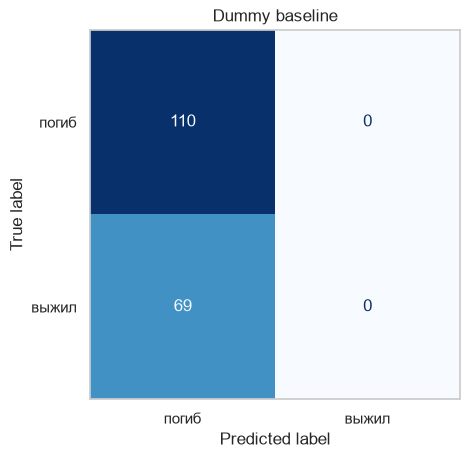

In [12]:
# Baseline: всегда самый частый класс
baseline = Pipeline([("prep", preprocess_tree), ("model", DummyClassifier(strategy="most_frequent"))])
baseline.fit(X_train, y_train)
evaluate("Dummy baseline", baseline)

Baseline всегда отвечает «погиб». Accuracy у него 0.615, хотя модели как таковой нет. Precision, Recall и F1 равны 0: он не нашёл ни одного выжившего. Поэтому смотреть только на accuracy нельзя.

## Decision Tree

Дерево решений — цепочка вопросов «да/нет» по одному признаку. Каждый вопрос выбирается так, чтобы после разделения группы стали «чище». Чем глубже дерево, тем сильнее оно подстраивается под train, поэтому подбираем:
- глубину `max_depth`;
- минимум пассажиров в листе `min_samples_leaf`;
- критерий «чистоты» `criterion`: gini или entropy.

Лучшие параметры: {'model__min_samples_leaf': 1, 'model__max_depth': 3, 'model__criterion': 'entropy'}
F1 на фолдах кросс-валидации: [0.757 0.681 0.835 0.743 0.745]
F1 CV = 0.752 ± 0.049
F1 train = 0.781, F1 test = 0.776
Accuracy = 0.832, Precision = 0.800, Recall = 0.754


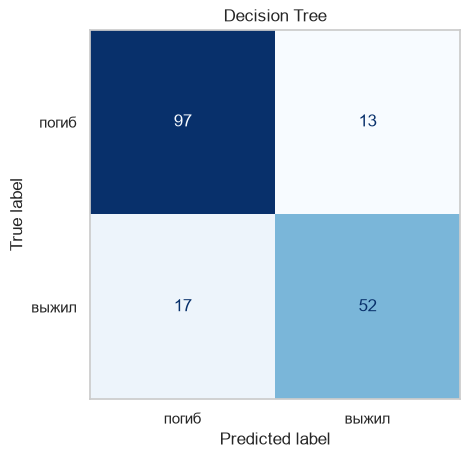

In [13]:
# Decision Tree
dt_search = RandomizedSearchCV(
    Pipeline([("prep", preprocess_tree), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_distributions={
        "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
        "model__min_samples_leaf": [1, 2, 5, 10, 20],
        "model__criterion": ["gini", "entropy"],
    },
    n_iter=20, scoring="f1", cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
dt_search.fit(X_train, y_train)
print("Лучшие параметры:", dt_search.best_params_)
evaluate("Decision Tree", dt_search.best_estimator_)

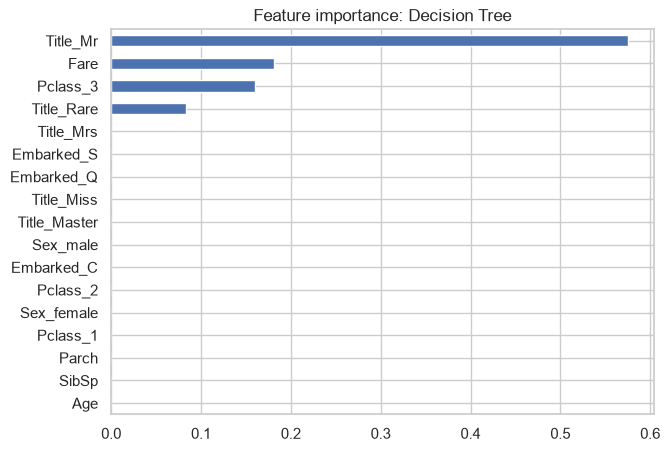

In [14]:
pd.Series(models["Decision Tree"]["model"].feature_importances_, index=feature_names).sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Feature importance: Decision Tree")
plt.show()

- **Лучшие параметры:** дерево глубиной 3 (всего 3 вопроса подряд), критерий entropy.
- **Кросс-валидация:** F1 = 0.752 ± 0.049. На разных фолдах результат от 0.68 до 0.84: дерево чувствительно к тому, какие пассажиры попали в обучение.
- **Тест:** F1 = 0.776, порог 0.70 пройден. В матрице ошибок 17 FN и 13 FP.
- **Переобучение.** F1 на train 0.781, на тесте 0.776 — практически одинаково, переобучения нет. Дерево маленькое и не может запомнить отдельных пассажиров.
- **Feature importance.**
  - Первый вопрос в корне — `Title_Mr` (0.58): взрослый мужчина или нет.
  - Дальше идут цена билета (0.18), 3-й класс (0.16) и редкие обращения (0.08).
  - Остальные признаки дерево не использует вовсе. Возраста, например, нет, потому что за детей уже «отвечает» обращение Master.

## Random Forest

Случайный лес — много деревьев. Каждое учится на своей случайной выборке пассажиров, а ответ леса — голосование. Ошибки отдельных деревьев при голосовании гасятся, поэтому лес устойчивее одного дерева. Подбираем:
- число деревьев `n_estimators`;
- их глубину `max_depth`;
- `min_samples_leaf`;
- сколько признаков дерево смотрит в каждом узле — `max_features`.

Лучшие параметры: {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_features': None, 'model__max_depth': None}


F1 на фолдах кросс-валидации: [0.759 0.721 0.812 0.762 0.738]
F1 CV = 0.758 ± 0.031
F1 train = 0.915, F1 test = 0.760
Accuracy = 0.827, Precision = 0.817, Recall = 0.710


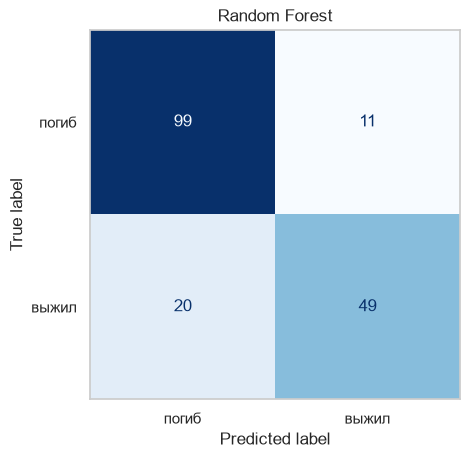

In [15]:
# Random Forest
rf_search = RandomizedSearchCV(
    Pipeline([("prep", preprocess_tree), ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
    param_distributions={
        "model__n_estimators": [100, 200, 300, 500],
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", 0.5, None],
    },
    n_iter=20, scoring="f1", cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print("Лучшие параметры:", rf_search.best_params_)
evaluate("Random Forest", rf_search.best_estimator_)

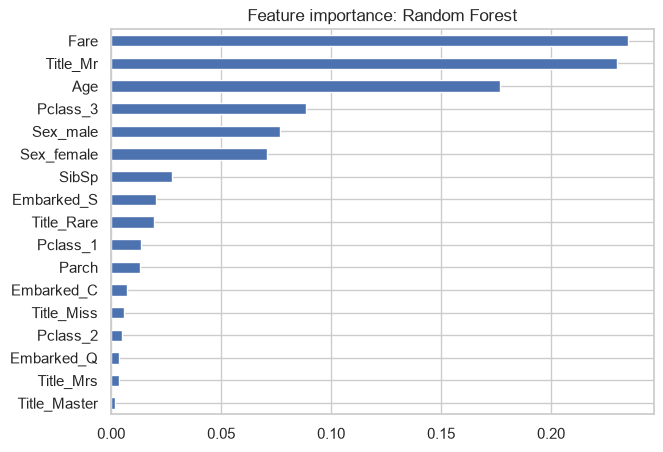

In [16]:
pd.Series(models["Random Forest"]["model"].feature_importances_, index=feature_names).sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Feature importance: Random Forest")
plt.show()

- **Лучшие параметры:** 300 деревьев без ограничения глубины, в листе минимум 2 пассажира, в каждом узле доступны все признаки.
- **Кросс-валидация:** F1 = 0.758 ± 0.031. Разброс меньше, чем у одного дерева: лес устойчивее.
- **Тест:** F1 = 0.760, порог пройден. В матрице ошибок 20 FN и 11 FP.
- **Переобучение.** F1 на train 0.915 заметно выше, чем на тесте. Деревья в лесу глубокие и почти запоминают свою выборку. Но голосование это сглаживает: F1 на кросс-валидации и на тесте одинаковые (0.758 и 0.760).
- **Feature importance.**
  - Главные признаки: `Fare` (0.24), `Title_Mr` (0.23), `Age` (0.18), затем 3-й класс (0.09) и пол (`Sex_male` + `Sex_female` = 0.15).
  - **Сравнение с Decision Tree.** Верхушка совпадает: обращение Mr, цена билета, 3-й класс. Но лес распределяет важность шире и использует ещё возраст и пол, которых у дерева нет. В лесе сотни разных деревьев, и разные деревья опираются на разные признаки.
  - У `Fare` и `Age` много разных значений, а этот способ подсчёта важности обычно такие признаки немного завышает.

## Gradient Boosting

Бустинг тоже строит много деревьев, но по очереди: каждое следующее исправляет ошибки уже построенных. Подбираем:
- число деревьев `n_estimators`;
- шаг `learning_rate` — насколько сильно каждое дерево исправляет предыдущие;
- глубину деревьев `max_depth`.

Лучшие параметры: {'model__n_estimators': 50, 'model__max_depth': 5, 'model__learning_rate': 0.1}


F1 на фолдах кросс-валидации: [0.781 0.785 0.827 0.743 0.74 ]
F1 CV = 0.775 ± 0.032
F1 train = 0.920, F1 test = 0.769
Accuracy = 0.832, Precision = 0.820, Recall = 0.725


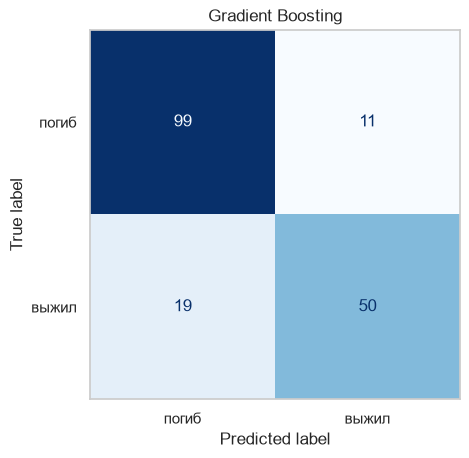

In [17]:
# Gradient Boosting
gb_search = RandomizedSearchCV(
    Pipeline([("prep", preprocess_tree), ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
    param_distributions={
        "model__n_estimators": [50, 100, 150, 200, 300],
        "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "model__max_depth": [2, 3, 4, 5],
    },
    n_iter=20, scoring="f1", cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
gb_search.fit(X_train, y_train)
print("Лучшие параметры:", gb_search.best_params_)
evaluate("Gradient Boosting", gb_search.best_estimator_)

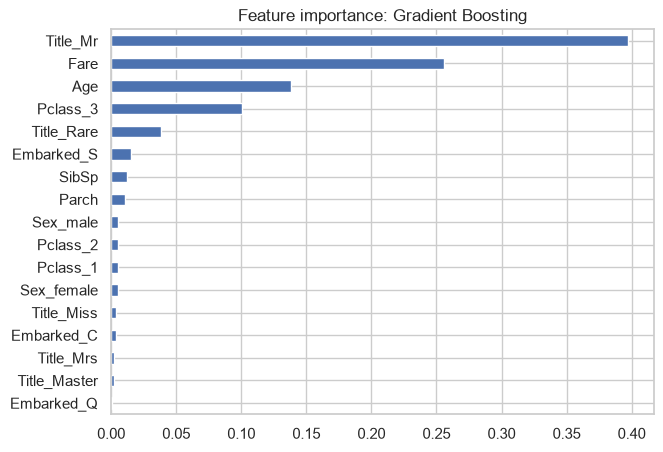

In [18]:
pd.Series(models["Gradient Boosting"]["model"].feature_importances_, index=feature_names).sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Feature importance: Gradient Boosting")
plt.show()

- **Лучшие параметры:** 50 деревьев глубиной 5, шаг 0.1.
- **Кросс-валидация:** F1 = 0.775 ± 0.032 — лучший результат среди всех моделей.
- **Тест:** F1 = 0.769, порог пройден. В матрице ошибок 19 FN и 11 FP.
- **Переобучение.** F1 на train 0.920 заметно выше, чем на тесте: деревья глубиной 5 подстраиваются под train. Но на кросс-валидации и на тесте бустинг всё равно не хуже остальных.
- **Feature importance.**
  - Главные признаки: `Title_Mr` (0.40), `Fare` (0.26), `Age` (0.14) и 3-й класс (0.10).
  - Пол почти не используется (около 0.01): обращение Mr уже говорит, что это мужчина.
  - **Сравнение с Random Forest.** Четыре главных признака у них общие, но бустинг сильнее сосредоточен на `Title_Mr`. Первые деревья бустинга сразу делят пассажиров по самому сильному признаку, а следующие лишь уточняют ответ. В лесе деревья строятся независимо, и одни делят по полу, другие по обращению, поэтому важность «размазывается» между этими признаками.

## SVM

SVM ищет границу между выжившими и погибшими с максимальным зазором — чтобы ближайшие пассажиры обоих классов были от неё как можно дальше. Подбираем:
- `C` — насколько строго штрафовать ошибки на train;
- `gamma` — насколько «изогнутой» может быть граница.

**Масштабирование для SVM обязательно.** Зазор — это расстояние между пассажирами. Без масштабирования расстояние почти целиком определяет цена билета (0–512), а возраст и one-hot признаки (0 или 1) почти не влияют.

Лучшие параметры: {'model__gamma': 0.01, 'model__C': 30}


F1 на фолдах кросс-валидации: [0.778 0.725 0.835 0.755 0.752]
F1 CV = 0.769 ± 0.037
F1 train = 0.775, F1 test = 0.794
Accuracy = 0.849, Precision = 0.839, Recall = 0.754


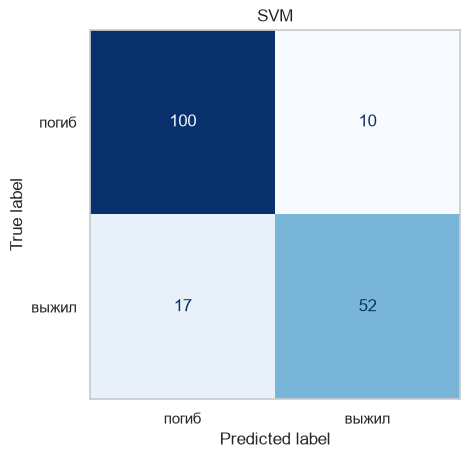

In [19]:
# SVM (с масштабированием)
svm_search = RandomizedSearchCV(
    Pipeline([("prep", preprocess_scaled), ("model", SVC(kernel="rbf"))]),
    param_distributions={
        "model__C": [0.1, 0.3, 1, 3, 10, 30],
        "model__gamma": ["scale", 0.01, 0.03, 0.1, 0.3, 1],
    },
    n_iter=20, scoring="f1", cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
svm_search.fit(X_train, y_train)
print("Лучшие параметры:", svm_search.best_params_)
evaluate("SVM", svm_search.best_estimator_)

In [20]:
# Тот же SVM без масштабирования
svm_no_scaling = Pipeline([("prep", preprocess_tree), ("model", clone(models["SVM"]["model"]))])
print("F1 CV без масштабирования:", cross_val_score(svm_no_scaling, X_train, y_train, cv=cv, scoring="f1").mean().round(3))

F1 CV без масштабирования: 0.707


- **Лучшие параметры:** `C=30`, `gamma=0.01`.
- **Кросс-валидация:** F1 = 0.769 ± 0.037.
- **Тест:** F1 = 0.794 — лучший результат на тесте. Порог пройден. В матрице ошибок 17 FN и 10 FP.
- **Переобучение.** F1 на train 0.775, на тесте 0.794 — переобучения нет.
- **Без масштабирования** F1 на кросс-валидации падает с 0.769 до 0.707: модель хуже видит все признаки, кроме цены билета.

## KNN

KNN для нового пассажира находит k самых похожих пассажиров из train и смотрит, выжили ли они. Подбираем:
- число соседей `n_neighbors`;
- `weights` — одинаковый ли голос у всех соседей, или у более близких он больше;
- `p` — как считать расстояние: 1 — сумма разниц по признакам, 2 — обычное расстояние «по прямой».

**Масштабирование для KNN критично.** «Похожесть» — это расстояние. Без масштабирования разница в цене билета на 100 весит намного больше, чем разница в возрасте на 50 лет, и соседи подбираются почти только по цене билета.

Лучшие параметры: {'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 5}
F1 на фолдах кросс-валидации: [0.759 0.707 0.8   0.796 0.708]
F1 CV = 0.754 ± 0.041
F1 train = 0.820, F1 test = 0.750
Accuracy = 0.821, Precision = 0.814, Recall = 0.696


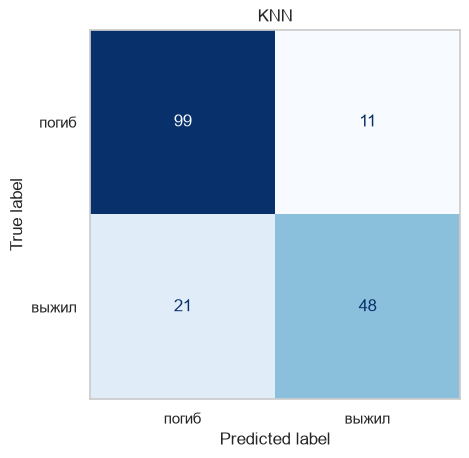

In [21]:
# KNN (с масштабированием)
knn_search = RandomizedSearchCV(
    Pipeline([("prep", preprocess_scaled), ("model", KNeighborsClassifier())]),
    param_distributions={
        "model__n_neighbors": list(range(3, 31, 2)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    n_iter=20, scoring="f1", cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
knn_search.fit(X_train, y_train)
print("Лучшие параметры:", knn_search.best_params_)
evaluate("KNN", knn_search.best_estimator_)

In [22]:
# Тот же KNN без масштабирования
knn_no_scaling = Pipeline([("prep", preprocess_tree), ("model", clone(models["KNN"]["model"]))])
print("F1 CV без масштабирования:", cross_val_score(knn_no_scaling, X_train, y_train, cv=cv, scoring="f1").mean().round(3))

F1 CV без масштабирования: 0.684


- **Лучшие параметры:** 5 соседей с одинаковым голосом, расстояние `p=1`.
- **Кросс-валидация:** F1 = 0.754 ± 0.041.
- **Тест:** F1 = 0.750, порог пройден. В матрице ошибок 21 FN и 11 FP.
- **Переобучение.** F1 на train 0.820, на тесте 0.750. Разрыв небольшой: при 5 соседях модель немного подстраивается под train.
- **Без масштабирования** F1 на кросс-валидации падает с 0.754 до 0.684.

## Итоговая таблица

In [23]:
# Итоговая таблица
results_table = pd.DataFrame(results).T
results_table["F1 > 0.70"] = np.where(results_table["F1"] > 0.70, "да", "нет")
results_table

,Accuracy,Precision,Recall,F1,F1 train,F1 CV,F1 > 0.70
Dummy baseline,0.615,0.000,0.000,0.000,0.000,0.000,нет
Decision Tree,0.832,0.800,0.754,0.776,0.781,0.752,да
Random Forest,0.827,0.817,0.710,0.760,0.915,0.758,да
Gradient Boosting,0.832,0.820,0.725,0.769,0.920,0.775,да
SVM,0.849,0.839,0.754,0.794,0.775,0.769,да
KNN,0.821,0.814,0.696,0.750,0.820,0.754,да


**Порог F1 > 0.70 прошли все пять моделей:** SVM — 0.794, Decision Tree — 0.776, Gradient Boosting — 0.769, Random Forest — 0.760, KNN — 0.750.

**Почему результаты разные и почему они близки.**
- **Близкие результаты.** Почти вся полезная информация лежит в 3–4 признаках: обращение/пол, класс, цена билета, возраст. Любая модель после подбора параметров её находит. Поэтому все модели дают F1 на кросс-валидации от 0.75 до 0.78.
- **Разница внутри шума.** Разница между моделями (около 0.02) меньше, чем разброс F1 между фолдами одной модели (±0.03–0.05). Строго говоря, модели почти равны.
- **Precision выше Recall у всех.** Модели осторожнее говорят «выжил»: Precision 0.80–0.84 при Recall 0.70–0.75. Чаще всего пропускают выживших мужчин.
- **Переобучение.** Сильнее всего подстраиваются под train лес и бустинг (F1 на train выше 0.9). Меньше всего — неглубокое дерево и SVM.
- **Лучшая модель.** Выбираем её по F1 на кросс-валидации, а не по тесту: это **Gradient Boosting** (0.775). На тесте чуть выше SVM, но выбирать модель по тесту нельзя.

## Feature importance: сравнение моделей

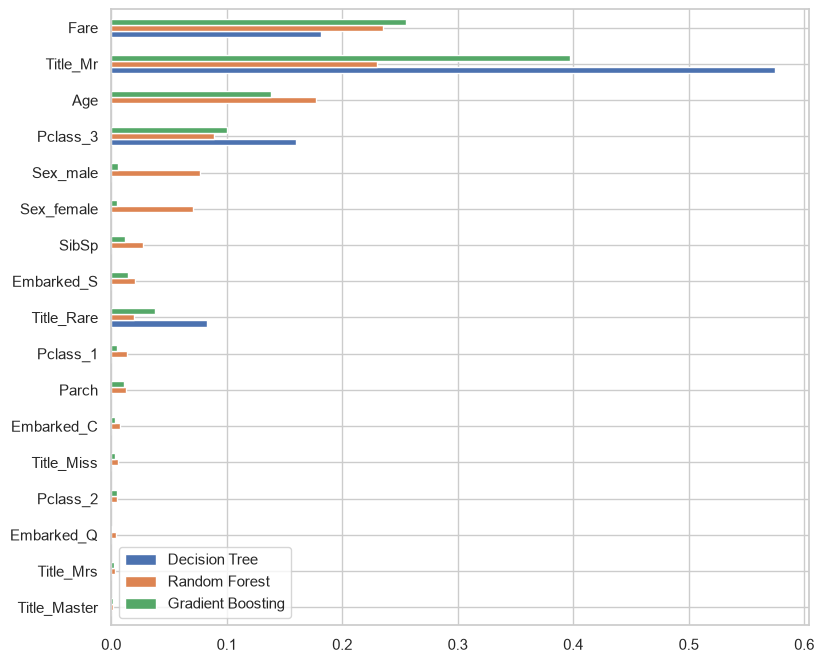

,Decision Tree,Random Forest,Gradient Boosting
Fare,0.182,0.235,0.256
Title_Mr,0.575,0.230,0.397
Age,0.000,0.177,0.138
Pclass_3,0.160,0.089,0.100
Sex_male,0.000,0.077,0.005
Sex_female,0.000,0.071,0.005
SibSp,0.000,0.028,0.012
Embarked_S,0.000,0.020,0.015
Title_Rare,0.083,0.019,0.038
Pclass_1,0.000,0.013,0.005


In [24]:
# Сравнение важности признаков у трёх моделей на деревьях
importances = pd.DataFrame({
    name: models[name]["model"].feature_importances_
    for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]
}, index=feature_names)

importances.sort_values("Random Forest").plot(kind="barh", figsize=(9, 8))
plt.show()
importances.sort_values("Random Forest", ascending=False)

- **Все три модели на деревьях** считают главными одни и те же признаки: обращение Mr, цену билета и 3-й класс, а лес и бустинг ещё и возраст. `SibSp`, `Parch` и `Embarked` почти не важны.
- **Это совпадает с анализом данных:**
  - сильнее всего доля выживших различалась по полу и обращению (Mr — 15%, Mrs — 79%) и по классу (65% в 1-м, 24% в 3-м);
  - возраст важен для детей;
  - порт посадки сам по себе ничего не значит.
- **Пол и обращение подменяют друг друга.** Дерево и бустинг берут `Title_Mr` и почти не используют `Sex`, хотя пол явно важен: обращение Mr уже содержит информацию о поле.

**Можно ли сказать, что важный для модели признак — причина выживания? Нет.**
- Важность показывает, на что модель опирается при прогнозе, а не почему люди выжили.
- Обращение Mr и пол важны не сами по себе: спасало правило «сначала женщины и дети».
- Цена билета важна, потому что дорогой билет — это 1-й класс, а его каюты были ближе к шлюпкам.
- Причину можно установить только экспериментом. По наблюдаемым данным видна лишь связь.

In [25]:
# Проверка: что будет, если дать лесу номер пассажира
X_train_id = X_train.join(df["PassengerId"])
rf_id = Pipeline([
    ("prep", ColumnTransformer(preprocess_tree.transformers + [("id", "passthrough", ["PassengerId"])])),
    ("model", clone(models["Random Forest"]["model"])),
])
rf_id.fit(X_train_id, y_train)

print("F1 CV без PassengerId:", round(results["Random Forest"]["F1 CV"], 3))
print("F1 CV с PassengerId: ", round(cross_val_score(rf_id, X_train_id, y_train, cv=cv, scoring="f1").mean(), 3))
pd.Series(rf_id["model"].feature_importances_, index=rf_id["prep"].get_feature_names_out()).sort_values(ascending=False).head(5)

F1 CV без PassengerId: 0.758


F1 CV с PassengerId:  0.743


cat__Title_Mr     0.220
num__Fare         0.173
id__PassengerId   0.156
num__Age          0.123
cat__Pclass_3     0.083
dtype: float64

**Проверка на признаки, которые идентифицируют пассажира.**
- Если дать лесу `PassengerId`, модель ставит его на 3-е место по важности (0.156). Но F1 на кросс-валидации от этого не растёт, а падает: с 0.758 до 0.743. Модель просто запоминает номера обучающих пассажиров, а на новых людях это мешает.
- В нашей модели таких признаков нет: `PassengerId`, `Name`, `Ticket` и `Cabin` исключены. Значит, качество не связано с запоминанием конкретных людей.
- Модель сильно опирается на пол и обращение. Для исторической задачи это отражает реальность. Но если бы похожую модель применяли для решений о людях (кредит, страховка), учёт пола был бы дискриминацией.

## Анализ ошибок лучшей модели

In [26]:
# Анализ ошибок лучшей модели (выбираем по F1 на кросс-валидации, не по тесту)
best_name = results_table.drop("Dummy baseline")["F1 CV"].astype(float).idxmax()
print("Лучшая модель:", best_name)

test_info = df.loc[X_test.index, ["Name", "Sex", "Age", "Pclass", "Title", "Fare", "SibSp", "Parch", "Survived"]]
test_info["Predicted"] = predictions[best_name]
test_info["Result"] = "верно"
test_info.loc[(test_info["Survived"] == 0) & (test_info["Predicted"] == 1), "Result"] = "FP"
test_info.loc[(test_info["Survived"] == 1) & (test_info["Predicted"] == 0), "Result"] = "FN"
test_info["Result"].value_counts()

Лучшая модель: Gradient Boosting


Result
верно    149
FN        19
FP        11
Name: count, dtype: int64

Лучшая модель по кросс-валидации — Gradient Boosting. На тесте она верно ответила для 149 пассажиров из 179 и ошиблась 30 раз: 19 FN и 11 FP. Выживших модель пропускает почти вдвое чаще, чем ошибается в обратную сторону.

In [27]:
pd.crosstab([test_info["Sex"], test_info["Pclass"]], test_info["Result"], margins=True)

Result         FN  FP  верно  All
Sex    Pclass                    
female 1        0   1     14   15
       2        0   1     17   18
       3        5   4     19   28
male   1        4   4     22   30
       2        2   0     14   16
       3        8   1     63   72
All            19  11    149  179

**Где модель ошибается чаще всего.**
- **Женщины 3-го класса:** 9 ошибок из 28 (5 FN и 4 FP). В этой группе выживает примерно половина, и по признакам выжившие почти не отличаются от погибших.
- **Мужчины 3-го класса:** 9 ошибок из 72, почти все FN. Модель всем говорит «погиб» и пропускает немногих выживших.
- **Мужчины 1-го класса:** 8 ошибок из 30 (4 FN и 4 FP). Выжила примерно треть, и модели трудно понять, кто именно.
- **Женщины 1-го и 2-го класса:** по одной ошибке. Почти все они выжили, и модель это знает.

In [28]:
test_info[test_info["Result"] != "верно"].sort_values(["Result", "Sex", "Pclass"])

,Name,Sex,Age,Pclass,Title,Fare,SibSp,Parch,Survived,Predicted,Result
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.000,3,Mrs,17.400,1,0,1,0,FN
216,"Honkanen, Miss. Eliina",female,27.000,3,Miss,7.925,0,0,1,0,FN
279,"Abbott, Mrs. Stanton (Rosa Hunt)",female,35.000,3,Mrs,20.250,1,1,1,0,FN
431,"Thorneycroft, Mrs. Percival (Florence Kate White)",female,NaN,3,Mrs,16.100,1,0,1,0,FN
142,"Hakkarainen, Mrs. Pekka Pietari (Elin Matilda ...",female,24.000,3,Mrs,15.850,1,0,1,0,FN
712,"Taylor, Mr. Elmer Zebley",male,48.000,1,Mr,52.000,1,0,1,0,FN
55,"Woolner, Mr. Hugh",male,NaN,1,Mr,35.500,0,0,1,0,FN
23,"Sloper, Mr. William Thompson",male,28.000,1,Mr,35.500,0,0,1,0,FN
587,"Frolicher-Stehli, Mr. Maxmillian",male,60.000,1,Mr,79.200,1,1,1,0,FN
17,"Williams, Mr. Charles Eugene",male,NaN,2,Mr,13.000,0,0,1,0,FN


**Почему модель ошиблась — несколько примеров.**
- **Coutts, Master. Eden** и **Goldsmith, Master. Frank** — мальчики 9 лет из 3-го класса, выжили. Модель сказала «погиб». Среди мальчиков (Master) выживает только около половины, а в 3-м классе шансы ниже, и модель склонилась к «погиб».
- **Honkanen, Miss. Eliina** и другие выжившие женщины 3-го класса — модель сказала «погибла». В этой группе шансы примерно 50/50.
- **Allison, Miss. Helen Loraine** — девочка 2 лет из 1-го класса, погибла. Модель сказала «выжила». По данным всё говорило о спасении, а причина гибели — в обстоятельствах, которых в таблице нет.
- **Lam, Mr. Len** — мужчина 3-го класса, погиб. Модель сказала «выжил»: у него высокая цена билета (56.5). Но `Fare` — это цена билета на всю группу, один билет был на нескольких человек, поэтому для одного пассажира цена завышена.
- **Crosby, Capt. Edward** — мужчина 70 лет с редким обращением, 1-й класс, погиб. Модель сказала «выжил». Пассажиров с редкими обращениями мало, и модель плохо их понимает.

Общая причина: выживание сильно зависело от случая — где человек был в момент крушения, успел ли к шлюпке, остался ли с семьёй. Этого в данных нет.

## Итоговые выводы
1. **Подготовка данных.**
   - Убрали признаки-идентификаторы (`PassengerId`, `Name`, `Ticket`) и почти пустой `Cabin`. Из имени взяли только обращение.
   - Пропуски заполнили медианой и самым частым значением, категории закодировали one-hot.
   - Все преобразования обучаются только на train.
2. **Подбор и кросс-валидация.** Параметры каждой модели подобраны через `RandomizedSearchCV` по F1 на 5-фолдовой кросс-валидации внутри train. Тест использован только для финальной оценки.
3. **Результаты.**
   - Baseline: accuracy 0.615, F1 = 0.
   - Порог F1 > 0.70 прошли все пять моделей (0.750–0.794).
   - Лучшая по кросс-валидации — Gradient Boosting (0.775).
4. **Масштабирование.** Для SVM и KNN оно обязательно, без него F1 падает. Деревьям оно не нужно.
5. **Главные признаки** у всех моделей — обращение/пол, цена билета, класс и возраст. Это совпадает с анализом данных, но не доказывает причинность.
6. **Ошибки.** Модели чаще пропускают выживших (FN). Больше всего ошибок среди женщин 3-го класса и мужчин 1-го и 3-го класса.